# DCF valuation model - built step by step from base inputs

## 0. Importing libraries

In [38]:
"""
The script is organised in 7 sections. Each section prints its own result,
so the whole calculation can be followed line by line when running the file.

"""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. INPUTS - the only values to edit

In [39]:
COMPANY_NAME = "XYZ Corp"

# Balance sheet and market data (last reported year)
REVENUE_0 = 10_000.0          # revenue, $m
DEBT = 3_000.0                # gross financial debt, $m
CASH = 500.0                  # cash, $m
SHARES = 500.0                # number of shares, millions
PRICE = 32.00                 # current share price, $

# EV to equity bridge
OPERATING_CASH_PCT = 0.02     # cash needed to run the business, % of revenue year 0
LEASE_LIABILITIES = 0.0       # $m, none assumed for the sample company
PENSION_PROVISIONS = 0.0      # $m, none assumed for the sample company
MINORITY_INTERESTS = 0.0      # $m, none assumed for the sample company
DILUTIVE_SHARES = 0.0         # net new shares, millions, none assumed

# Operating assumptions - one value per forecast year
REVENUE_GROWTH = [0.08, 0.07, 0.06, 0.05, 0.04]
EBIT_MARGIN = [0.18, 0.18, 0.19, 0.19, 0.20]
TAX_RATE = 0.25

# Reinvestment, as a % of the revenue of the same year
DA_PCT = 0.05                 # depreciation & amortisation
CAPEX_PCT = 0.06              # capital expenditure

# Working capital components, as a % of the revenue of the same year
INVENTORY_PCT = 0.12
RECEIVABLES_PCT = 0.15
PAYABLES_PCT = 0.12

# Cost of capital
RISK_FREE = 0.030             # risk-free rate
MARKET_PREMIUM = 0.055        # equity market risk premium
UNLEVERED_BETA = 0.90         # asset beta of the sector
CREDIT_SPREAD = 0.020         # spread over the risk-free rate

TERMINAL_GROWTH = 0.020       # perpetual growth rate
RONIC_SPREAD = 0.020          # terminal return on new capital = WACC + this spread

print("=" * 60)
print(f"DCF VALUATION - {COMPANY_NAME}")
print("=" * 60)
print(f"\nRevenue year 0 : {REVENUE_0:,.0f} $m")
print(f"Forecast period: {len(REVENUE_GROWTH)} years")

DCF VALUATION - XYZ Corp

Revenue year 0 : 10,000 $m
Forecast period: 5 years


## 2. COST OF CAPITAL (Ke); COST OF DEBT (Kd) & WACC

In [40]:
# Market capitalisation uses the CURRENT share price, not the price the
# DCF will produce, otherwise the model would be circular.
market_cap = SHARES * PRICE
debt_to_equity = DEBT / market_cap
print(f"\nMarket capitalisation : {market_cap:,.0f} $m")
print(f"Debt / equity         : {debt_to_equity:.2f}")


Market capitalisation : 16,000 $m
Debt / equity         : 0.19


In [41]:
# Hamada: relever the sector asset beta with the company capital structure
levered_beta = UNLEVERED_BETA * (1 + (1 - TAX_RATE) * debt_to_equity)
print(f"Levered beta (Hamada) : {levered_beta:.2f}")

Levered beta (Hamada) : 1.03


In [42]:
# CAPM: the return equity holders require
cost_of_equity = RISK_FREE + levered_beta * MARKET_PREMIUM
print(f"Cost of equity (CAPM) : {cost_of_equity:.2%}")

Cost of equity (CAPM) : 8.65%


In [43]:
# Cost of debt, before and after the tax shield
cost_of_debt = RISK_FREE + CREDIT_SPREAD
cost_of_debt_net = cost_of_debt * (1 - TAX_RATE)
print(f"Cost of debt pre-tax  : {cost_of_debt:.2%}")
print(f"Cost of debt after tax: {cost_of_debt_net:.2%}")

Cost of debt pre-tax  : 5.00%
Cost of debt after tax: 3.75%


In [44]:
# Weights, at market value
total_capital = market_cap + DEBT
weight_equity = market_cap / total_capital
weight_debt = DEBT / total_capital
print(f"Weight of equity      : {weight_equity:.1%}")
print(f"Weight of debt        : {weight_debt:.1%}")

Weight of equity      : 84.2%
Weight of debt        : 15.8%


In [45]:
WACC = weight_equity * cost_of_equity + weight_debt * cost_of_debt_net
print(f"\n>>> WACC = {WACC:.2%}")


>>> WACC = 7.87%


## 3. FREE CASH FLOW PROJECTION

In [46]:
years = range(1, len(REVENUE_GROWTH) + 1)
df = pd.DataFrame(index=years)
df.index.name = "Year"

# Revenue(n) = Revenue(n-1) x (1 + growth): compounded with a cumulative product
df["Revenue"] = REVENUE_0 * np.cumprod(np.array(REVENUE_GROWTH) + 1)

df["EBIT"] = df["Revenue"] * EBIT_MARGIN
df["NOPAT"] = df["EBIT"] * (1 - TAX_RATE)
df["D&A"] = df["Revenue"] * DA_PCT
df["CapEx"] = df["Revenue"] * CAPEX_PCT
display(df.T.style.format("{:,.0f}").set_caption("Operating forecast ($m)"))

Year,1,2,3,4,5
Revenue,"10,800","11,556","12,249","12,862","13,376"
EBIT,"1,944","2,080","2,327","2,444","2,675"
NOPAT,"1,458","1,560","1,746","1,833","2,006"
D&A,540,578,612,643,669
CapEx,648,693,735,772,803


In [47]:
def net_working_capital(revenue):
    """NWC = inventory + receivables - payables, all driven by revenue."""
    inventory = revenue * INVENTORY_PCT
    receivables = revenue * RECEIVABLES_PCT
    payables = revenue * PAYABLES_PCT
    return inventory + receivables - payables

# Working capital ties up cash: only its VARIATION affects the cash flow.
# For year 1, the previous NWC is the one of year 0.
nwc_0 = net_working_capital(REVENUE_0)
df["NWC"] = net_working_capital(df["Revenue"])
df["Change in NWC"] = df["NWC"].diff().fillna(df["NWC"].iloc[0] - nwc_0)
display(df[["NWC", "Change in NWC"]].T.style.format("{:,.0f}")
        .set_caption("Working capital ($m)"))

Year,1,2,3,4,5
NWC,"1,620","1,733","1,837","1,929","2,006"
Change in NWC,120,113,104,92,77


## 4. FREE CASH FLOW, DISCOUNTING AND ENTERPRISE VALUE

In [48]:
# FCF = NOPAT + D&A - CapEx - change in NWC
df["FCF"] = df["NOPAT"] + df["D&A"] - df["CapEx"] - df["Change in NWC"]

# Discount factor = 1 / (1 + WACC) ** n
df["Discount factor"] = 1 / (1 + WACC) ** df.index
df["PV of FCF"] = df["FCF"] * df["Discount factor"]

# Full model, from revenue down to the discounted cash flow
rows = ["Revenue", "EBIT", "NOPAT", "D&A", "CapEx", "Change in NWC",
        "FCF", "Discount factor", "PV of FCF"]
labels = ["Revenue", "EBIT", "NOPAT", "(+) D&A", "(-) CapEx", "(-) Change in NWC",
          "Free cash flow", "Discount factor", "PV of FCF"]

summary = df[rows].T
summary.index = labels
summary.columns = [f"Y{year}" for year in df.index]

display(summary.style
        .format("{:,.0f}")
        .format("{:.3f}", subset=pd.IndexSlice[["Discount factor"], :])
        .set_properties(subset=pd.IndexSlice[["Free cash flow"], :],
                        **{"font-weight": "bold"})
        .set_caption("DCF model ($m)"))

pv_explicit = df["PV of FCF"].sum()
print(f"Sum of discounted FCF : {pv_explicit:,.0f} $m")

,Y1,Y2,Y3,Y4,Y5
Revenue,"10,800","11,556","12,249","12,862","13,376"
EBIT,"1,944","2,080","2,327","2,444","2,675"
NOPAT,"1,458","1,560","1,746","1,833","2,006"
(+) D&A,540,578,612,643,669
(-) CapEx,648,693,735,772,803
(-) Change in NWC,120,113,104,92,77
Free cash flow,"1,230","1,331","1,519","1,612","1,796"
Discount factor,0.927,0.859,0.797,0.738,0.685
PV of FCF,"1,140","1,144","1,210","1,191","1,229"


Sum of discounted FCF : 5,914 $m


In [49]:
# Terminal year: NOPAT grows at g and g / RONIC of it is reinvested.
# Working capital grows at g too; net capex is what remains of the reinvestment.
last_year = df.index[-1]

def terminal_fcf(growth, ronic):
    """FCF of the year after the forecast, from the value driver formula."""
    return df["NOPAT"].iloc[-1] * (1 + growth) * (1 - growth / ronic)

terminal_ronic = WACC + RONIC_SPREAD
reinvestment_rate = TERMINAL_GROWTH / terminal_ronic
nopat_terminal = df["NOPAT"].iloc[-1] * (1 + TERMINAL_GROWTH)
reinvestment_terminal = nopat_terminal * reinvestment_rate
nwc_change_terminal = df["NWC"].iloc[-1] * TERMINAL_GROWTH
net_capex_terminal = reinvestment_terminal - nwc_change_terminal
fcf_terminal = terminal_fcf(TERMINAL_GROWTH, terminal_ronic)
print(f"Terminal RONIC        : {terminal_ronic:.2%}")
print(f"Reinvestment rate     : {reinvestment_rate:.1%} of NOPAT")
print(f"Terminal NOPAT        : {nopat_terminal:,.0f} $m")
print(f"(-) Change in NWC     : {-nwc_change_terminal:,.0f} $m")
print(f"(-) Net capex         : {-net_capex_terminal:,.0f} $m")
print(f"Terminal FCF          : {fcf_terminal:,.0f} $m")

# Gordon Growth: value of every cash flow after the last forecast year
terminal_value = fcf_terminal / (WACC - TERMINAL_GROWTH)
pv_terminal = terminal_value * df["Discount factor"].iloc[-1]
print(f"Terminal value (Y{last_year})   : {terminal_value:,.0f} $m")
print(f"PV of terminal value  : {pv_terminal:,.0f} $m")

Terminal RONIC        : 9.87%
Reinvestment rate     : 20.3% of NOPAT
Terminal NOPAT        : 2,047 $m
(-) Change in NWC     : -40 $m
(-) Net capex         : -374 $m
Terminal FCF          : 1,632 $m
Terminal value (Y5)   : 27,788 $m
PV of terminal value  : 19,024 $m


In [50]:
enterprise_value = pv_explicit + pv_terminal
print(f"\n>>> Enterprise value = {enterprise_value:,.0f} $m")
print(f"    of which terminal value: {pv_terminal / enterprise_value:.1%}")


>>> Enterprise value = 24,938 $m
    of which terminal value: 76.3%


## 5. FROM ENTERPRISE VALUE TO SHARE PRICE

In [51]:
# Only the cash the business does not need to operate goes to shareholders
operating_cash = min(CASH, REVENUE_0 * OPERATING_CASH_PCT)
excess_cash = CASH - operating_cash

non_equity_claims = (DEBT - excess_cash + LEASE_LIABILITIES
                     + PENSION_PROVISIONS + MINORITY_INTERESTS)
equity_value = enterprise_value - non_equity_claims
diluted_shares = SHARES + DILUTIVE_SHARES
implied_price = equity_value / diluted_shares
upside = implied_price / PRICE - 1

print(f"\nEnterprise value      : {enterprise_value:,.0f} $m")
print(f"(-) Gross debt        : {-DEBT:,.0f} $m")
print(f"(+) Excess cash       : {excess_cash:,.0f} $m  "
      f"(total {CASH:,.0f}, operating {operating_cash:,.0f})")
print(f"(-) Lease liabilities : {0 - LEASE_LIABILITIES:,.0f} $m")
print(f"(-) Pension provisions: {0 - PENSION_PROVISIONS:,.0f} $m")
print(f"(-) Minority interests: {0 - MINORITY_INTERESTS:,.0f} $m")
print(f"Equity value          : {equity_value:,.0f} $m")
print(f"Diluted shares        : {diluted_shares:,.1f} m  "
      f"(basic {SHARES:,.1f}, dilution {DILUTIVE_SHARES:,.1f})")
print(f"\n>>> Implied price = {implied_price:,.2f} $  (current: {PRICE:,.2f} $)")
print(f"    Upside / (downside): {upside:+.1%}")


Enterprise value      : 24,938 $m
(-) Gross debt        : -3,000 $m
(+) Excess cash       : 300 $m  (total 500, operating 200)
(-) Lease liabilities : 0 $m
(-) Pension provisions: 0 $m
(-) Minority interests: 0 $m
Equity value          : 22,238 $m
Diluted shares        : 500.0 m  (basic 500.0, dilution 0.0)

>>> Implied price = 44.48 $  (current: 32.00 $)
    Upside / (downside): +39.0%


In [52]:
# Sanity check: the exit multiple implied by the Gordon Growth formula
ebitda_last = df["EBIT"].iloc[-1] + df["D&A"].iloc[-1]
print(f"    Implied exit EV/EBITDA: {terminal_value / ebitda_last:,.1f}x")

    Implied exit EV/EBITDA: 8.3x


## 6. SENSITIVITY

In [53]:
wacc_range = np.arange(WACC - 0.01, WACC + 0.011, 0.005)
growth_range = np.arange(0.01, 0.031, 0.005)

sensitivity = pd.DataFrame(index=[f"{w:.2%}" for w in wacc_range],
                           columns=[f"{g:.2%}" for g in growth_range],
                           dtype=float)

for w in wacc_range:
    for g in growth_range:
        pv = (df["FCF"] / (1 + w) ** df.index).sum()
        tv = terminal_fcf(g, w + RONIC_SPREAD) / (w - g)
        ev = pv + tv / (1 + w) ** last_year
        sensitivity.loc[f"{w:.2%}", f"{g:.2%}"] = (ev - non_equity_claims) / diluted_shares

display(sensitivity.style
        .background_gradient(cmap="RdYlGn", axis=None)
        .format("{:,.2f}")
        .set_caption("Implied share price ($) — rows: WACC, columns: terminal growth"))

,1.00%,1.50%,2.00%,2.50%,3.00%
6.87%,50.69,51.95,53.43,55.22,57.43
7.37%,46.40,47.41,48.58,49.97,51.63
7.87%,42.71,43.53,44.48,45.57,46.85
8.37%,39.49,40.17,40.94,41.82,42.84
8.87%,36.66,37.23,37.87,38.59,39.42


In [ ]:
# Operating sensitivity: terminal EBITDA margin x revenue growth.
# The margin applies to the terminal year only, the forecast margins do not move.
# The growth shift applies to every forecast year, terminal growth does not move.
def price_operating(ebitda_margin, growth_shift):
    growth = np.array(REVENUE_GROWTH) + growth_shift
    revenue = REVENUE_0 * np.cumprod(1 + growth)
    previous = np.insert(revenue[:-1], 0, REVENUE_0)
    fcf = (revenue * np.array(EBIT_MARGIN) * (1 - TAX_RATE)
           + revenue * DA_PCT - revenue * CAPEX_PCT
           - (net_working_capital(revenue) - net_working_capital(previous)))
    pv = (fcf / (1 + WACC) ** df.index.values).sum()
    nopat = revenue[-1] * (1 + TERMINAL_GROWTH) * (ebitda_margin - DA_PCT) * (1 - TAX_RATE)
    tv = nopat * (1 - TERMINAL_GROWTH / terminal_ronic) / (WACC - TERMINAL_GROWTH)
    return (pv + tv / (1 + WACC) ** last_year - non_equity_claims) / diluted_shares

base_margin = EBIT_MARGIN[-1] + DA_PCT
margin_range = base_margin + np.array([-0.04, -0.02, 0.0, 0.02, 0.04])
shift_range = [-0.02, -0.01, 0.0, 0.01, 0.02]

operating = pd.DataFrame(
    [[price_operating(m, s) for s in shift_range] for m in margin_range],
    index=[f"{m:.1%}" for m in margin_range],
    columns=[f"{s * 100:+.0f} pt" for s in shift_range])

display(operating.style
        .background_gradient(cmap="RdYlGn", axis=None)
        .format("{:,.2f}")
        .set_caption("Implied share price ($) — rows: terminal EBITDA margin, "
                     "columns: shift in yearly revenue growth"))

,-2 pt,-1 pt,+0 pt,+1 pt,+2 pt
21.0%,33.69,35.25,36.87,38.54,40.27
23.0%,37.15,38.88,40.67,42.53,44.45
25.0%,40.61,42.51,44.48,46.51,48.63
27.0%,44.07,46.14,48.28,50.50,52.80
29.0%,47.53,49.77,52.08,54.49,56.98


**Note:** the EBITDA margin varies in the terminal year only. The margins of years 1 to 5 stay at their base values.

## 7. CHARTS

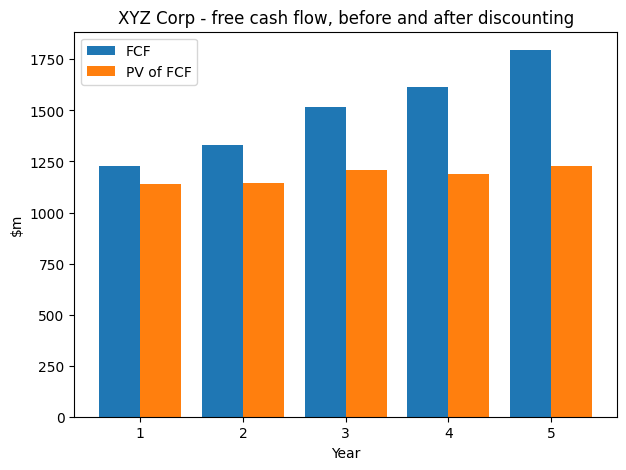

In [54]:
fig, ax1 = plt.subplots(figsize=(7, 5))

years_axis = np.array(df.index)
ax1.bar(years_axis - 0.2, df["FCF"], width=0.4, label="FCF")
ax1.bar(years_axis + 0.2, df["PV of FCF"], width=0.4, label="PV of FCF")
ax1.set_title(f"{COMPANY_NAME} - free cash flow, before and after discounting")
ax1.set_xlabel("Year")
ax1.set_ylabel("$m")
ax1.set_xticks(years_axis)
ax1.legend()
plt.show()